## Mining Supply Sales Performance Analysis

In [1]:
import pandas as pd
import numpy as np 
import matplotlib.pyplot as plt
import seaborn as sns 
plt.style.use("default")
sns.set_theme()

In [5]:
df = pd.read_csv(r"C:\Users\DICKSON ANTIRI\Downloads\mining_supply_sales.csv")
df.head()

,sale_date,product_name,quantity,amount
0,10/07/2025,Cement,10,500
1,10/07/2025,Excavator Oil,5,1500
2,10/07/2025,Helmet,20,300
3,10/07/2025,Gloves,15,225
4,11/07/2025,Cement,12,600


In [12]:
#df.isnull().sum()
#df.duplicated().sum()
df["sale_date"] = pd.to_datetime(df["sale_date"], dayfirst=True)

In [17]:
df["day"] = df["sale_date"].dt.day
df["weekday"] = df["sale_date"].dt.day_name()
df["week"] = df["sale_date"].dt.isocalendar().week    


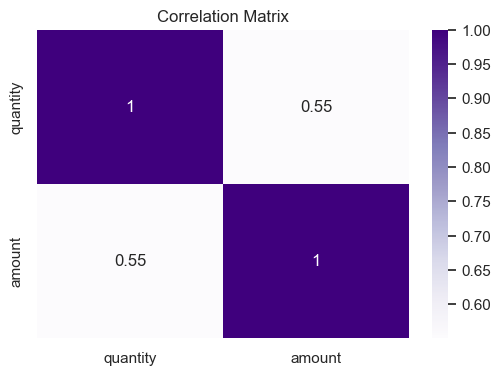

In [80]:
# correlation heatmap
numeric_cols = ["quantity","amount"]
corr = df[numeric_cols].corr()
plt.figure(figsize=(6,4))
sns.heatmap(corr,annot=True,cmap="Purples")
plt.title("Correlation Matrix")
plt.show()

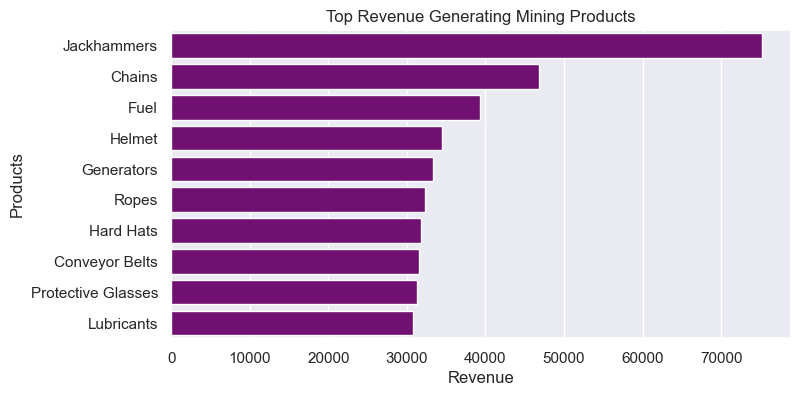

In [70]:
# Top revenue by product
top_products = df.groupby("product_name")["amount"].sum().sort_values(ascending=False).head(10)
plt.figure(figsize=(8,4))

sns.barplot(x=top_products.values,y=top_products.index,color="purple")
plt.title("Top Revenue Generating Mining Products")
plt.xlabel("Revenue")
plt.ylabel("Products")
plt.show()         

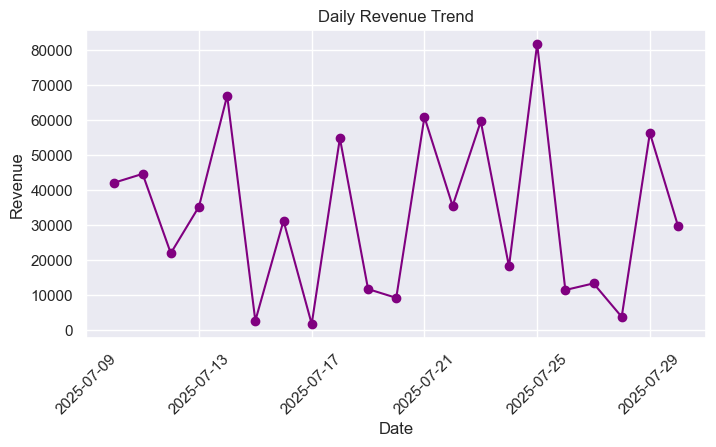

In [34]:
daily_sales = df.groupby("sale_date")["amount"].sum()
plt.figure(figsize=(8,4))

plt.plot(daily_sales.index,daily_sales.values,marker="o",color="purple")
plt.title("Daily Revenue Trend")
plt.xlabel("Date")
plt.ylabel("Revenue")
plt.xticks(rotation=45)
plt.show()

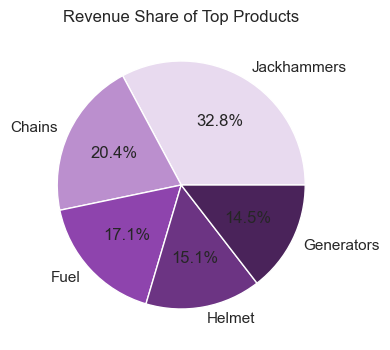

In [82]:
# Product Revenue share
product_sales = df.groupby("product_name")["amount"].sum().sort_values(ascending=False).head()
plt.figure(figsize=(4,5))

plt.pie(product_sales.values,labels=product_sales.index,autopct="%1.1f%%",colors=["#E8DAEF","#BB8FCE","#8E44AD","#6C3483","#4A235A"])
plt.title("Revenue Share of Top Products")
plt.show()

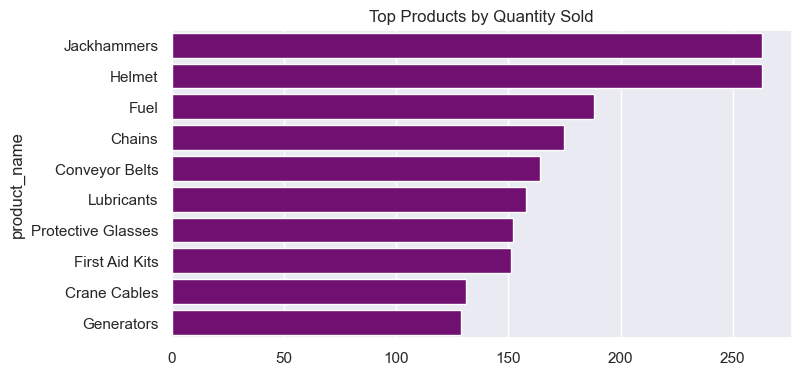

In [47]:
Quantity = df.groupby("product_name")["quantity"].sum().sort_values(ascending=False).head(10)
plt.figure(figsize=(8,4))

sns.barplot(x=Quantity.values,y=Quantity.index,color="purple")
plt.title("Top Products by Quantity Sold")
plt.show()

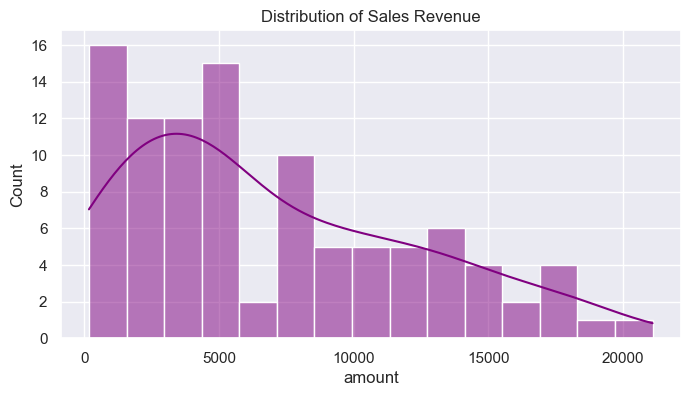

In [54]:
plt.figure(figsize=(8,4))
sns.histplot(df["amount"],bins=15,kde=True,color="purple")
plt.title("Distribution of Sales Revenue")
plt.show()


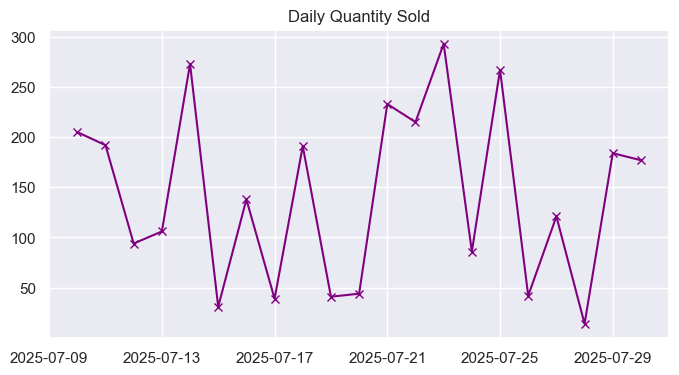

In [58]:
daily_quantity = df.groupby("sale_date")["quantity"].sum()
plt.figure(figsize=(8,4))

plt.plot(daily_quantity.index,daily_quantity.values,marker="x",color="Purple")
plt.title("Daily Quantity Sold")
plt.show()

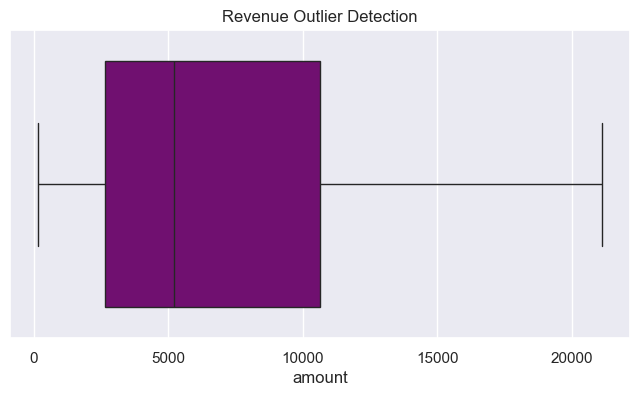

In [63]:
plt.figure(figsize=(8,4))
sns.boxplot(x=df["amount"],color="purple")
plt.title("Revenue Outlier Detection")
plt.show()

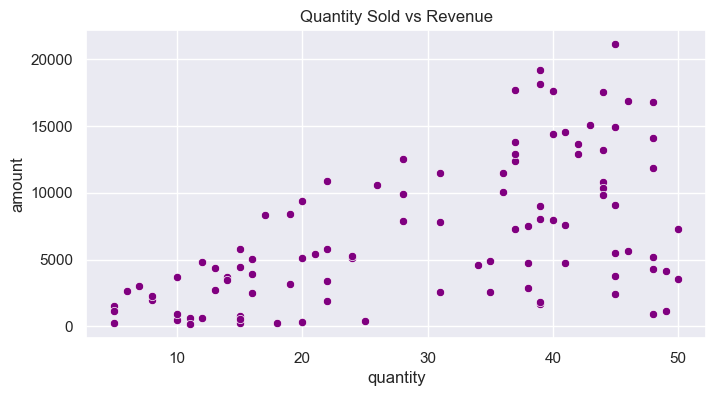

In [69]:
plt.figure(figsize=(8,4))
sns.scatterplot(x="quantity",y="amount",data=df,color="purple")
plt.title("Quantity Sold vs Revenue")
plt.show()

product_name
Jackhammers           75173
Chains                46801
Fuel                  39265
Helmet                34467
Generators            33281
Ropes                 32321
Hard Hats             31744
Conveyor Belts        31506
Protective Glasses    31271
Lubricants            30794
Name: amount, dtype: int64